In [1]:
import math

# Step 1: Dataset
data = [
    ['Young', 'High', 'No'],
    ['Young', 'Low', 'No'],
    ['Mid', 'High', 'Yes'],
    ['Old', 'Medium', 'Yes'],
    ['Old', 'Low', 'Yes']
]


In [2]:
data

[['Young', 'High', 'No'],
 ['Young', 'Low', 'No'],
 ['Mid', 'High', 'Yes'],
 ['Old', 'Medium', 'Yes'],
 ['Old', 'Low', 'Yes']]

In [3]:
# Step 2: Entropy Function
def entropy(data):
    total = len(data)
    labels = [row[-1] for row in data]
    yes = labels.count('Yes')
    no = labels.count('No')
    if yes == 0 or no == 0:
        return 0
    p_yes, p_no = yes/total, no/total
    return -p_yes*math.log2(p_yes) - p_no*math.log2(p_no)

In [4]:
entropy(data)

0.9709505944546686

In [5]:



# Step 3: Split function
def split(data, index, value):
    print("+++++++")
    print(data)
    print(index)
    print(value)
    print("+++++++")
    return [row for row in data if row[index] == value]

# Step 4: Info Gain
def info_gain(data, index):
    base_entropy = entropy(data)
    print("--------",index)
    print(data[0])
    values = set(row[index] for row in data)# We collect all **unique values** for that feature (column).
    weighted_entropy = 0
    print(values)
    for v in values:
        subset = split(data, index, v)
        weighted_entropy += (len(subset)/len(data)) * entropy(subset)
    return base_entropy - weighted_entropy

# Step 5: Calculate IG for each attribute
attributes = ['Age', 'Income']
for i, attr in enumerate(attributes):
    print(f"{attr} IG: {info_gain(data, i):.3f}")


-------- 0
['Young', 'High', 'No']
{'Old', 'Young', 'Mid'}
+++++++
[['Young', 'High', 'No'], ['Young', 'Low', 'No'], ['Mid', 'High', 'Yes'], ['Old', 'Medium', 'Yes'], ['Old', 'Low', 'Yes']]
0
Old
+++++++
+++++++
[['Young', 'High', 'No'], ['Young', 'Low', 'No'], ['Mid', 'High', 'Yes'], ['Old', 'Medium', 'Yes'], ['Old', 'Low', 'Yes']]
0
Young
+++++++
+++++++
[['Young', 'High', 'No'], ['Young', 'Low', 'No'], ['Mid', 'High', 'Yes'], ['Old', 'Medium', 'Yes'], ['Old', 'Low', 'Yes']]
0
Mid
+++++++
Age IG: 0.971
-------- 1
['Young', 'High', 'No']
{'High', 'Low', 'Medium'}
+++++++
[['Young', 'High', 'No'], ['Young', 'Low', 'No'], ['Mid', 'High', 'Yes'], ['Old', 'Medium', 'Yes'], ['Old', 'Low', 'Yes']]
1
High
+++++++
+++++++
[['Young', 'High', 'No'], ['Young', 'Low', 'No'], ['Mid', 'High', 'Yes'], ['Old', 'Medium', 'Yes'], ['Old', 'Low', 'Yes']]
1
Low
+++++++
+++++++
[['Young', 'High', 'No'], ['Young', 'Low', 'No'], ['Mid', 'High', 'Yes'], ['Old', 'Medium', 'Yes'], ['Old', 'Low', 'Yes']]
1
Mediu

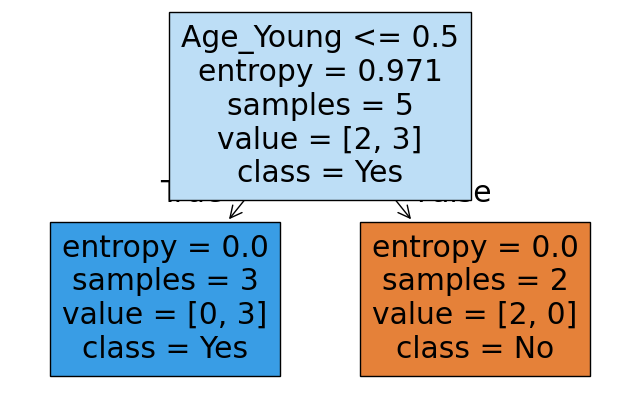

In [2]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
import pandas as pd
import matplotlib.pyplot as plt

# Prepare dataset
df = pd.DataFrame({
    'Age': ['Young', 'Young', 'Mid', 'Old', 'Old'],
    'Income': ['High', 'Low', 'High', 'Medium', 'Low'],
    'Buys_Laptop': ['No', 'No', 'Yes', 'Yes', 'Yes']
})

# Convert categorical to numeric
df_encoded = pd.get_dummies(df[['Age', 'Income']])
X = df_encoded
y = df['Buys_Laptop']

# Train Decision Tree
clf = DecisionTreeClassifier(criterion='entropy', random_state=0)
clf.fit(X, y)

# Visualize
plt.figure(figsize=(8,5))
plot_tree(clf, feature_names=X.columns, class_names=clf.classes_, filled=True)
plt.show()
